# 04 · Feature engineering

**Goal recap:** for each customer at a cutoff date, predict next-6-month `y_buy` and `y_spend` from their history up to that date.
Notebook 03 built the rows (snapshots) and the bar to beat ("copy the last 6 months": AUC 0.75, Spearman 0.54).

**This notebook's question:** *what can we compute about a customer on the cutoff date that tells us about their next 6 months, without accidentally using anything after it?*

### How to think about features (the framework)
Each feature is a **hypothesis** about behaviour: *"customers who X are more likely to buy / spend more because Y."* We group them into families:

| Family | Hypothesis |
|---|---|
| **RFM** (recency, frequency, monetary) | recent, frequent, big spenders keep being so |
| **Rates** | long-run habit, measured per month so it's comparable across cutoffs |
| **Tenure** | customers who survived the early months are stickier |
| **Timing** | each customer has a rhythm; silence only matters relative to *their* rhythm |
| **Trend** | growing accounts grow, shrinking ones shrink |
| **Basket / breadth** | wholesalers buy big and broad, and behave differently from small shops |
| **Returns** | returns signal dissatisfaction, or value that won't stick |
| **Calendar** | does the next 6 months contain the Sep–Nov peak? (known in advance, so not leakage) |
| **Country** | market differences |

### Two rules every feature must obey
1. **Point-in-time correctness:** a feature at cutoff `c` uses only data on or before `c`. Enforced *inside* `build_features(…, as_of)`, so no caller can get it wrong.
2. **Same meaning at every cutoff:** a feature must mean the same thing at training cutoffs (≤ 190 days of history) as at the test cutoff (555 days). Otherwise the model learns a relationship that silently breaks in production (**train/serve skew**, section 4).

### 🧠 Predict first
1. Which single feature will correlate most with next-6-month spend?
2. Will the **overdue ratio** (silence ÷ the customer's usual gap) beat plain **recency** at predicting `y_buy`?
3. "Lifetime spend so far" is computed with no future data at all. How could it *still* mislead the model at the test cutoff?

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.clean import CLEAN_PARQUET, RETURNS_PARQUET
from src.split import TRAIN_CUTOFFS, FINAL_CUTOFFS, VAL_CUTOFF, TEST_CUTOFF, DATA_START, ONE_DAY, before_test
from src.features import CATALOG, NUMERIC_FEATURES, build_features, build_feature_table, purchase_days

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)
SEED = 42
np.random.seed(SEED)

PROCESSED = Path(CLEAN_PARQUET).parent
purchases = before_test(pd.read_parquet(CLEAN_PARQUET))
returns = before_test(pd.read_parquet(RETURNS_PARQUET))
snapshots = pd.read_parquet(PROCESSED / "snapshot_targets.parquet")

## 1. The feature catalog
Every feature has a one-line reason to exist and a known missing-value rule. The catalog lives in `src/features.py`, and the builder asserts it matches the columns, so the documentation can't drift from the code.

In [2]:
CATALOG.style.hide(axis="index").set_properties(**{"text-align": "left"})

feature,family,definition,why_it_should_predict,missing_when
recency_days,RFM,days since last purchase day,silence is the main sign of lapsing (nb 02: 83% → 53%),never
n_days_30d,RFM,purchase days in last 30 days,recent frequency = current engagement,never (0)
n_days_90d,RFM,purchase days in last 90 days,recent frequency = current engagement,never (0)
n_days_180d,RFM,purchase days in last 180 days,recent frequency = current engagement,never (0)
spend_30d,RFM,£ spend in last 30 days,recent value; spend_180d is the naive baseline,never (0)
spend_90d,RFM,£ spend in last 90 days,recent value; spend_180d is the naive baseline,never (0)
spend_180d,RFM,£ spend in last 180 days,recent value; spend_180d is the naive baseline,never (0)
days_per_month,Rate,purchase days per 30 days since first purchase,"long-run habit, comparable across cutoffs",never
spend_per_month,Rate,£ per 30 days since first purchase,long-run value; catches dormant big customers,never
tenure_days,Tenure,days since first purchase (≤ history available),survivors of early churn are stickier; grows with history → skew risk,never


**Features deliberately *not* built:**
- **Share of orders in Sep–Nov** (the customer's own seasonality): training cutoffs (Jan–Jun 2010) have **no** Sep–Nov history at all, so the feature would be empty during model selection.
- **Weekday / hour habits:** weak hypothesis for a 6-month value target; optional in the plan, skipped to keep the feature set focused.
- **Raw lifetime totals** (lifetime spend, lifetime order count, lifetime product count, lifetime max order): replaced by rates or 180-day windows. Section 4 shows why.

## 2. Build features for every snapshot

In [3]:
table = build_feature_table(purchases, returns, snapshots)
train = table[table["cutoff"].isin(TRAIN_CUTOFFS)]
print(f"Feature table: {table.shape[0]:,} rows × {len(CATALOG)} features | training rows: {len(train):,}")
table[table["cutoff"] == VAL_CUTOFF].head(3).T

Feature table: 33,254 rows × 27 features | training rows: 11,787


,28972,28973,28974
Customer ID,12346,12347,12348
cutoff,2010-12-09 00:00:00,2010-12-09 00:00:00,2010-12-09 00:00:00
y_spend,0.0,1494.16,1167.24
y_buy,0,1,1
y_ltv,0.0,448.248,350.172
recency_days,164,2,73
n_days_30d,0.0,1.0,0.0
n_days_90d,0.0,2.0,1.0
n_days_180d,1.0,2.0,1.0
spend_30d,0.0,711.79,0.0


## 3. Leakage checks: prove it, don't assume it

### 3a. Future-invariance test
If the features truly ignore the future, then **adding fake transactions after the cutoff must change nothing**. And adding one *on* the cutoff day must change something (the boundary is in the right place).

In [4]:
as_of = VAL_CUTOFF
base = build_features(purchases, returns, as_of)

fake_future = purchases.sample(5000, random_state=SEED).assign(
    InvoiceDate=as_of + pd.Timedelta(days=1, hours=10), Quantity=lambda d: d["Quantity"] * 100, Spend=lambda d: d["Spend"] * 100)
fake_returns = returns.sample(500, random_state=SEED).assign(InvoiceDate=as_of + pd.Timedelta(days=2))
poisoned = build_features(pd.concat([purchases, fake_future]), pd.concat([returns, fake_returns]), as_of)
pd.testing.assert_frame_equal(base, poisoned)
print("✅ 5,000 huge fake purchases + 500 returns AFTER the cutoff → features identical")

cid = base.index[(base["recency_days"] > 30) & (base["spend_90d"] > 0)][0]  # non-trivial values to check
same_day = purchases[purchases["Customer ID"] == cid].head(1).assign(InvoiceDate=as_of + pd.Timedelta(hours=23))
moved = build_features(pd.concat([purchases, same_day]), returns, as_of)
print(f"✅ one purchase at 23:00 ON the cutoff day → customer {cid}: recency "
      f"{base.loc[cid, 'recency_days']:.0f} → {moved.loc[cid, 'recency_days']:.0f} days")

✅ 5,000 huge fake purchases + 500 returns AFTER the cutoff → features identical


✅ one purchase at 23:00 ON the cutoff day → customer 12348: recency 73 → 0 days


### 3b. Hand check: recompute two features from raw lines for one customer

In [5]:
lines = purchases[(purchases["Customer ID"] == cid) & (purchases["InvoiceDate"] < as_of + ONE_DAY)]
last_day = lines["InvoiceDate"].max().normalize()
in_90 = lines[lines["InvoiceDate"].dt.normalize() > as_of - pd.Timedelta(days=90)]
print(f"recency : by hand {(as_of - last_day).days:>8} | builder {base.loc[cid, 'recency_days']:>8.0f}")
print(f"spend_90d: by hand {in_90['Spend'].sum():>8.2f} | builder {base.loc[cid, 'spend_90d']:>8.2f}")

recency : by hand       73 | builder       73
spend_90d: by hand   221.16 | builder   221.16


### 3c. A taste of what leakage looks like
Same idea as `spend_180d`, but computed **forgetting the cutoff**: total spend over all data up to the test date. For a training row, that total *includes the target window*.

In [6]:
all_data_spend = purchases.groupby("Customer ID")["Spend"].sum().rename("spend_all_data")
check = train.merge(all_data_spend, left_on="Customer ID", right_index=True)
leak = pd.Series({
    "honest: spend_180d": check["spend_180d"].corr(check["y_spend"], method="spearman"),
    "LEAKY: spend over all data": check["spend_all_data"].corr(check["y_spend"], method="spearman"),
}).round(3)
leak.to_frame("Spearman with y_spend (training rows)")

,Spearman with y_spend (training rows)
honest: spend_180d,0.573
LEAKY: spend over all data,0.863


**Takeaway:** the leaky version looks like a much stronger feature, *because it partly is the answer*. A model built on it would shine offline and fail in production, where the future isn't available.
That's why the cutoff filter lives inside the feature builder, not in the notebook. Notebook 11 measures how much each kind of leak inflates the metrics.

## 4. The subtler trap: train/serve skew from history length
No future data at all, and still a problem. Training cutoffs see **at most ~190 days** of history (the data starts Dec 2009); the test cutoff sees **555 days**.
A raw "lifetime spend" therefore grows **just because more history exists**, not because the customer changed.

To see that cleanly, follow a **fixed group of steady customers** (first purchase in Dec 2009, and a purchase in every one of the 7 calendar quarters from Q4 2009 to Q2 2011) across cutoffs.
Their behaviour is stable, so a well-designed feature should be roughly flat.

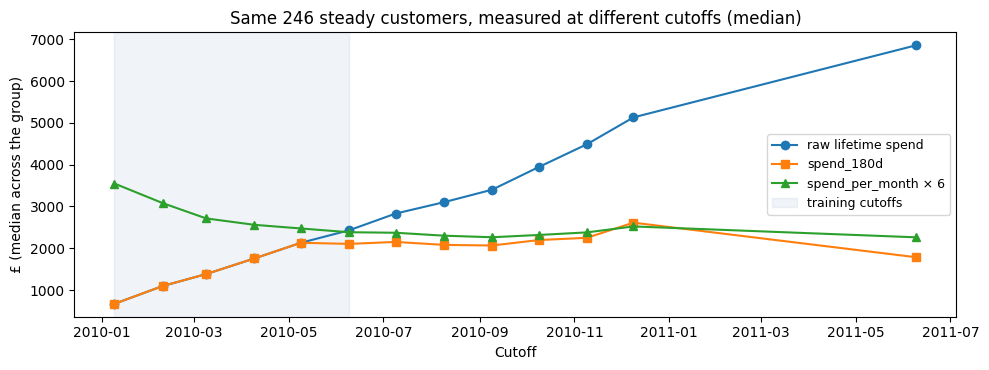

,history_days,raw lifetime spend,spend_per_month × 6,spend_180d
cutoff,,,,
2010-01-09,39,673.0,3548.0,673.0
2010-02-09,70,1097.0,3081.0,1097.0
2010-03-09,98,1383.0,2714.0,1383.0
2010-04-09,129,1757.0,2561.0,1757.0
2010-05-09,159,2132.0,2474.0,2132.0
2010-06-09,190,2431.0,2384.0,2105.0
2010-07-09,220,2831.0,2371.0,2152.0
2010-08-09,251,3102.0,2301.0,2081.0
2010-09-09,282,3401.0,2264.0,2066.0


In [7]:
d_all = purchase_days(purchases, TEST_CUTOFF)
quarters = d_all.assign(q=d_all["day"].dt.to_period("Q")).groupby("Customer ID")["q"].nunique()
first = d_all.groupby("Customer ID")["day"].min()
steady = quarters[(quarters >= 7) & (first < "2010-01-01")].index

rows = []
for c in FINAL_CUTOFFS + [TEST_CUTOFF]:
    life = purchase_days(purchases, c).groupby("Customer ID")["spend"].sum().reindex(steady)
    f = build_features(purchases, returns, c).reindex(steady)
    rows.append({"cutoff": c, "history_days": (c - DATA_START).days, "raw lifetime spend": life.median(),
                 "spend_per_month × 6": f["spend_per_month"].median() * 6, "spend_180d": f["spend_180d"].median()})
skew = pd.DataFrame(rows).set_index("cutoff")

fig, ax = plt.subplots(figsize=(10, 3.8))
for col, m in [("raw lifetime spend", "o"), ("spend_180d", "s"), ("spend_per_month × 6", "^")]:
    ax.plot(skew.index, skew[col], marker=m, label=col)
ax.axvspan(TRAIN_CUTOFFS[0], TRAIN_CUTOFFS[-1], color="#4C72B0", alpha=0.08, label="training cutoffs")
ax.set_title(f"Same {len(steady)} steady customers, measured at different cutoffs (median)")
ax.set_xlabel("Cutoff")
ax.set_ylabel("£ (median across the group)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
skew.round(0)

**Takeaway:** for customers whose behaviour **didn't change**, raw lifetime spend grows about **10×** between the first and the test cutoff, purely because the data window grows.
The two alternatives behave much better: `spend_180d` stabilises once its window has filled (from about June 2010), and the per-month rate (×6 to put it on the same scale) is roughly flat from about April.
Note what happens **inside the shaded training period**, though: the 180-day window is still filling up (rising from below) and the rate starts inflated (short tenures, with a 30-day floor, falling from above).
With ≤ 190 days of history *every* feature is a bit distorted during model selection. Rates and fixed windows keep that distortion small and temporary; raw lifetime totals make it permanent and growing.

**Why this matters:** the training rows teach the model what a lifetime spend of, say, £2,000 means *when history is ≤ 190 days*. At the test cutoff, the same £2,000 means a much smaller customer.
**Trees** would treat high test values like the highest values they saw in training. **Linear models** would extrapolate. Either way, predictions are biased upward, and **no leakage check catches it**,
because no future data was used.

**Design decisions taken:**
- Lifetime sums → **rates per month of tenure** (`spend_per_month`, `days_per_month`).
- Lifetime max order / product count → **180-day windows**.
- **Trend features** compare the last 90 days with the 90 before; with < 180 days of history the "before" window is partly before the data starts. They're set to **missing** then, which means all training cutoffs except June 2010.
- `tenure_days` still grows with history (≤ 190 in training, up to 555 at test). It's kept, but flagged: check its effect in notebook 08 and consider capping at the training maximum.
- **Interview line:** *"Point-in-time correctness isn't enough. Features also have to mean the same thing at training and scoring time, so I replaced lifetime totals with rates and fixed windows."*

## 5. Which features carry signal? (training rows only)
Spearman correlation of each feature with each target, computed **only on training snapshots**. Validation is for comparing *models*, so we don't peek at it to choose features.

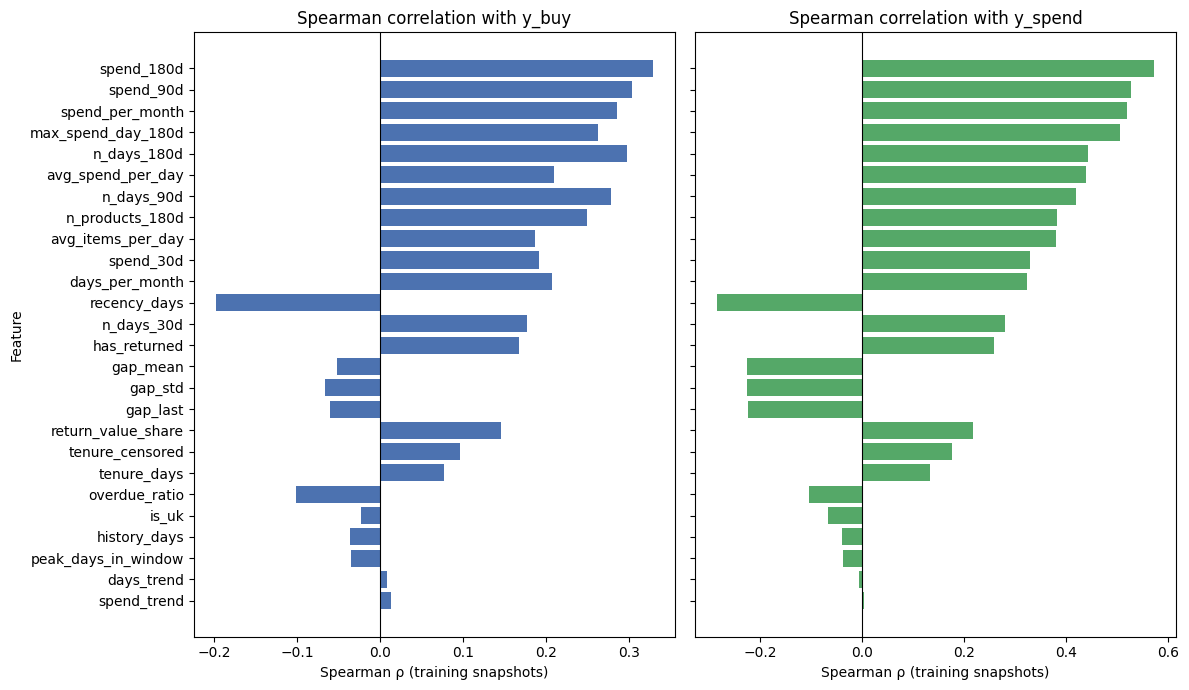

,y_buy,y_spend,missing
spend_180d,0.329,0.573,0.000
spend_90d,0.304,0.527,0.000
spend_per_month,0.285,0.519,0.000
max_spend_day_180d,0.262,0.505,0.000
n_days_180d,0.297,0.443,0.000
avg_spend_per_day,0.209,0.439,0.000
n_days_90d,0.278,0.420,0.000
n_products_180d,0.249,0.382,0.000
avg_items_per_day,0.187,0.380,0.000
spend_30d,0.192,0.330,0.000


In [8]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    signal = pd.DataFrame({
        "y_buy": train[NUMERIC_FEATURES].corrwith(train["y_buy"], method="spearman"),
        "y_spend": train[NUMERIC_FEATURES].corrwith(train["y_spend"], method="spearman"),
        "missing": train[NUMERIC_FEATURES].isna().mean(),
    }).sort_values("y_spend", key=abs)

fig, axes = plt.subplots(1, 2, figsize=(12, 7), sharey=True)
for ax, target, color in [(axes[0], "y_buy", "#4C72B0"), (axes[1], "y_spend", "#55A868")]:
    ax.barh(signal.index, signal[target], color=color)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Spearman correlation with {target}")
    ax.set_xlabel("Spearman ρ (training snapshots)")
axes[0].set_ylabel("Feature")
plt.tight_layout()
plt.show()
signal.sort_values("y_spend", key=abs, ascending=False).round(3)

**Takeaways:**
- **Recent spend dominates:** `spend_180d` (the naive baseline's own input) is the single strongest feature for both targets (ρ ≈ 0.57 with spend). Order size (`max_spend_day_180d`, `avg_spend_per_day`) and the long-run `spend_per_month` come next.
  The model's job is to **add** to `spend_180d`, not replace it.
- **Spend correlates more with `y_spend` than with `y_buy`** (0.57 vs. 0.33): the big *how much* signal is order size, while *whether* is more about engagement and recency.
  That supports the two-part view from our earlier discussion.
- **Recency** (ρ ≈ −0.2 with `y_buy`) is weaker than the spend and frequency windows. Those windows already contain recency information (a customer with spend in the last 30 days is, by definition, recent).
- **Trend features ≈ 0** here, but they only exist for the June cutoff (77% missing). This is "no evidence", not "evidence of nothing". Revisit at the final refit.
- **`peak_days_in_window` ≈ 0, and it can't be learned yet.** Across the 6 training cutoffs it rises from 0 to 91 days in lockstep with `history_days` (ρ ≈ 0.997, section 6).
  So during model selection *no* model can tell "the next 6 months contain the peak" apart from "this cutoff has more history". At validation the combination (373 days of history, 0 peak days) was never seen in training.
  The feature only becomes learnable at the **final refit**, where Jul–Dec cutoffs have *falling* peak days but *rising* history. Lesson: **a feature needs variation in the training data that isn't shared with another feature**.
- Caveat: univariate correlation ignores **interactions** and **redundancy**. Final feature selection uses permutation importance and group ablation (notebook 08).

### Recency vs. overdue ratio: does "relative silence" beat "absolute silence"?

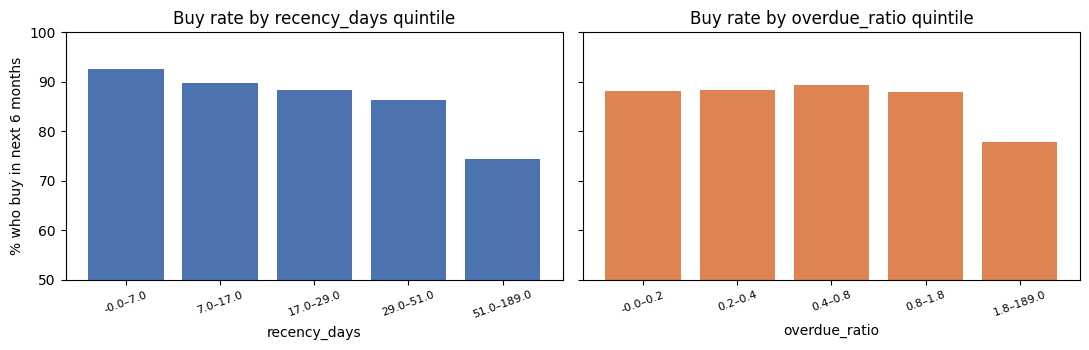

Customers with only 1 purchase day so far: 55% of training rows | buy rate 61% vs. 86% for repeat customers


In [9]:
multi = train.dropna(subset=["overdue_ratio"])  # customers with ≥ 2 purchase days
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col, color in [(axes[0], "recency_days", "#4C72B0"), (axes[1], "overdue_ratio", "#DD8452")]:
    q = multi.groupby(pd.qcut(multi[col], 5, duplicates="drop"), observed=True)["y_buy"].mean()
    ax.bar(range(len(q)), q.values * 100, color=color)
    ax.set_xticks(range(len(q)), [f"{iv.left:.1f}–{iv.right:.1f}" for iv in q.index], rotation=20, fontsize=8)
    ax.set_title(f"Buy rate by {col} quintile")
    ax.set_xlabel(col)
axes[0].set_ylabel("% who buy in next 6 months")
axes[0].set_ylim(50, 100)
plt.tight_layout()
plt.show()

one_day = train["gap_mean"].isna()
print(f"Customers with only 1 purchase day so far: {one_day.mean():.0%} of training rows | "
      f"buy rate {train.loc[one_day, 'y_buy'].mean():.0%} vs. {train.loc[~one_day, 'y_buy'].mean():.0%} for repeat customers")

**Takeaways:**
- Among repeat customers, the buy rate **declines gradually with recency** (93% → 86%) with a big drop for the most-silent fifth (74%). The **overdue ratio is flat until the customer is clearly overdue** (ratio above about 1.8), then drops.
  So "relative silence" matters mainly as a **threshold**: *past your usual rhythm* is the signal, not small variations. Trees can learn that threshold directly; a linear model would need a transformed version.
  In univariate terms it doesn't beat recency; whether it adds anything *on top of* recency is a question for the ablation in notebook 08.
- **Missing gap features are themselves informative:** one-day buyers (55% of training rows) return far less often than repeat customers.
  This is **not missing at random**, so imputing the median gap would erase a real signal. Notebook 05 will add a missing-indicator (or let LightGBM handle NaN natively).

## 6. Redundancy: which features say the same thing?

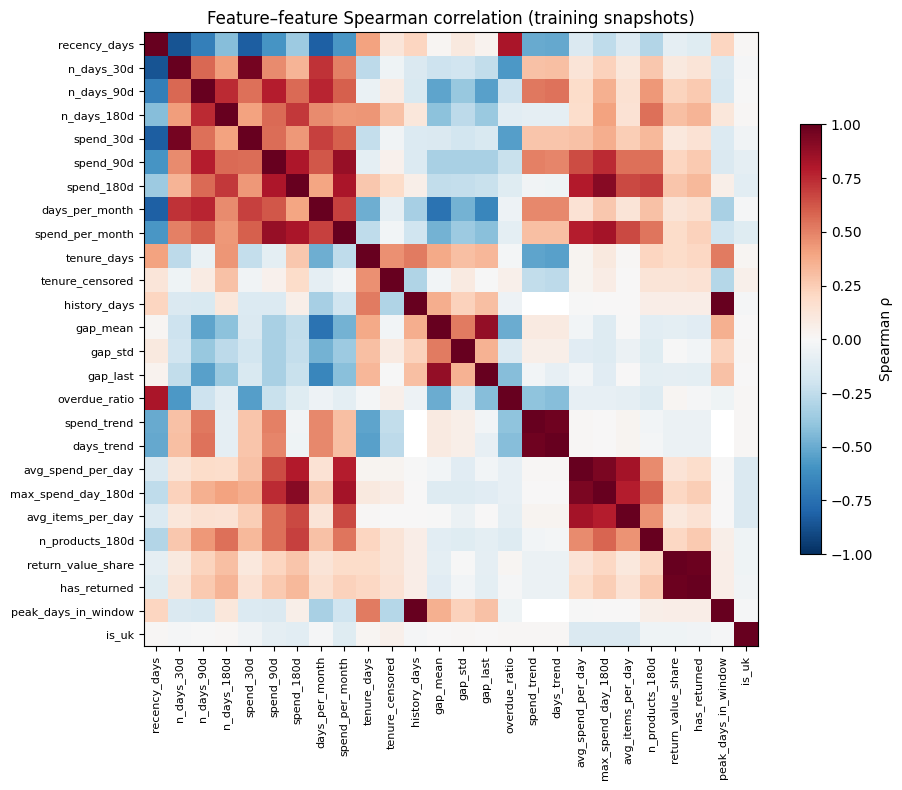

,level_0,level_1,rho
230,history_days,peak_days_in_window,0.997
315,return_value_share,has_returned,0.981
278,spend_trend,days_trend,0.974
27,n_days_30d,spend_30d,0.954
293,avg_spend_per_day,max_spend_day_180d,0.939
147,spend_180d,max_spend_day_180d,0.910
233,gap_mean,gap_last,0.877
117,spend_90d,spend_per_month,0.872
0,recency_days,n_days_30d,-0.859


In [10]:
corr = train[NUMERIC_FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman ρ")
ax.set_title("Feature–feature Spearman correlation (training snapshots)")
plt.tight_layout()
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().query("abs(rho) >= 0.85").sort_values("rho", ascending=False))
pairs.round(3)

**Takeaway:** the near-duplicates fall into three kinds:
- **By construction:** `has_returned` vs. `return_value_share`, `spend_trend` vs. `days_trend`, `gap_mean` vs. `gap_last`. They're different summaries of the same thing, so we could keep one of each pair.
- **Same behaviour, different lens:** spend in the last 30 days vs. purchase days in the last 30 days; average vs. maximum order size; recency vs. activity in the last 30 days (ρ ≈ −0.86).
- **A training-stage artefact:** `history_days` vs. `peak_days_in_window` (ρ ≈ 0.997). They're different concepts that happen to move together across the 6 training cutoffs (section 5).
  `history_days` is also constant within a cutoff: it describes the *snapshot*, not the customer.

**Implications:**
- **Linear / NN models:** correlated inputs make coefficients unstable and uninterpretable (multicollinearity). Regularisation (ridge) handles it; don't read individual coefficients.
- **Trees (LightGBM):** prediction quality is fine, but **importance gets split** across correlated features, so each looks less important than the group really is.
  That's why notebook 08 uses **group ablation** (drop a whole family) rather than trusting single-feature importances.

## 7. Hand-off to notebook 05 (preprocessing)

In [11]:
handoff = pd.DataFrame({
    "missing_share": train[NUMERIC_FEATURES].isna().mean(),
    "skewness": train[NUMERIC_FEATURES].skew(),
}).round(2)
is_binary = train[NUMERIC_FEATURES].nunique() <= 2
handoff["action_in_05"] = np.select(
    [handoff["missing_share"] > 0, (handoff["skewness"].abs() > 2) & ~is_binary],
    ["missing-indicator / native NaN", "log1p for linear & NN"], default="—")
print(handoff.query("action_in_05 != '—'").sort_values("skewness", ascending=False).to_string())
print(f"\nCountry: {table['country'].nunique()} levels in the table → encoding comparison in 05")

table.to_parquet(PROCESSED / "features.parquet", index=False)
print(f"Saved {len(table):,} rows → features.parquet")

                    missing_share  skewness                    action_in_05
return_value_share           0.00     47.48           log1p for linear & NN
avg_items_per_day            0.00     30.65           log1p for linear & NN
spend_30d                    0.00     19.96           log1p for linear & NN
max_spend_day_180d           0.00     19.53           log1p for linear & NN
spend_180d                   0.00     18.83           log1p for linear & NN
spend_per_month              0.00     17.60           log1p for linear & NN
spend_90d                    0.00     17.58           log1p for linear & NN
overdue_ratio                0.55     12.18  missing-indicator / native NaN
n_days_180d                  0.00      7.47           log1p for linear & NN
avg_spend_per_day            0.00      7.46           log1p for linear & NN
n_days_90d                   0.00      6.04           log1p for linear & NN
n_products_180d              0.00      5.75           log1p for linear & NN
days_per_mon

## 8. Summary

| Decision | Choice | Alternative not picked |
|---|---|---|
| Where to enforce the cutoff | inside `build_features(as_of)` + future-invariance test | filtering in each notebook (easy to forget once) |
| Lifetime totals | rates per month of tenure | raw totals: grow with history → train/serve skew |
| Trend with short history | missing | compute anyway: a fake "everyone is growing" signal |
| Behaviour unit | purchase day | invoice (a split order looks like a 0-day gap) |
| Feature screening | Spearman on **training rows only** | screening on validation: selection leaks into the model-comparison set |
| Missing gaps | keep as missing (informative) | median imputation: erases the one-day-buyer signal |
| Calendar feature | built, but flagged: collinear with `history_days` in training, so only learnable at the final refit | dropping it: test window *does* contain the peak, and the refit can learn it |

### 🧠 Interpret
1. Check your predictions: strongest feature, overdue vs. recency, and how lifetime spend misleads without any future data.
2. A colleague says: *"I filtered every query with `date <= cutoff`, so my features can't leak."* What problem from section 4 does that miss? Give a one-sentence example.
3. `spend_180d` is the strongest feature and also the baseline's only input. If the final model beats the baseline by a small margin, which **features** would you credit, and how would you prove it (hint: notebook 08)?
4. Why is it *wrong* to impute a one-day buyer's missing `gap_mean` with the median gap? What would the model then believe about them?
5. **ARQ:** a user's "lifetime FX volume" at month 2 vs. month 20 has the same skew problem. What rate or window feature would you use instead, and what's ARQ's version of "one-day buyers"?